# Community Health & Household Determinants Assessment
### Project Presentation Notebook | Dataset: `community_file Approve@Send.xlsx`

---

### Executive Overview
This notebook presents an end-to-end public health data analysis of a community health survey covering **249 individuals** (`บุคคล`, ages 1–88) across **66 households** (`ครัวเรือน`). The objective is to diagnose key epidemiological, behavioral, geriatric, and environmental risk drivers and translate statistical evidence into a prioritized, actionable community health intervention roadmap.

> **Four Headline Insights:**
> 1. **Super-Aged Community & NCD Surge:** **40.16%** (100/249) of residents are aged 60+, and **95.0%** of seniors live with at least one chronic disease ($\chi^2 = 111.29, p < 0.001$).
> 2. **Dietary Seasoning & Sugary Drinks Drive Risk:** Among residents aged 15+, **79.31%** of strong-flavor (`รสจัด`) eaters have chronic disease vs. **16.92%** of mild-flavor eaters ($\chi^2 = 70.21, p < 0.001$). Regular sugary beverage intake hits **80.0%** in teens (15–17) and **74.0%** in seniors (60+).
> 3. **Unsupervised Geriatric Fall & Dementia Risk:** Among seniors, **28.0%** suffered $\ge 2$ falls in the past 6 months and **22.0%** screen positive for suspected dementia—yet **64.3%** (18/28) of recurrent fallers and **50.0%** (11/22) of suspected dementia cases have **no caregiver**.
> 4. **Economic Stress Tracks Domestic Conflict & Poor Sanitation:** **53.03%** (35/66) of households report poor family dynamics (including **12.12%** domestic violence), concentrated sharply in low-income households averaging **6,095–6,250 THB/month** vs. **17,129 THB/month** in harmonious homes ($p < 0.001$). Meanwhile, **72.73%** fail to sort waste properly and **78.13%** of vector-affected homes perform no vector elimination.

---
## 1. Data Ingestion, Schema Hygiene & Quality Audit

Field-collected Excel datasets require programmatic sanitization before statistical modeling. Our ingestion pipeline resolves five specific structural issues discovered in `community_file Approve@Send.xlsx`:

1. **OpenXML Stylesheet Repair:** The raw workbook contains a style attribute (`family > 14`) in `xl/styles.xml` that triggers an `openpyxl` validation error; repairing this XML in memory enables clean, reproducible loading.
2. **Table Separation (`ครัวเรือน`):** Rows `1–66` hold raw household records, whereas rows `69–115` contain embedded report summary tables duplicated in sheet `หัวข้อ 5 ครัวเรือน`. We slice strictly to the 66 valid household records.
3. **String Standardization:** Stripping leading/trailing whitespace consolidates split categories in `BMI-4-` (`'น้ำหนักเกิน'`, `'  น้ำหนักเกิน'`, `' น้ำหนักเกิน'` $ightarrow$ **97** records) and removes draft template annotations from `Thai CVD Risk Score -4-` and `คะแนน ADL-4-`.
4. **Zero-Variance & Filter Audit:** Six columns are 100% `'ไม่เกี่ยวข้อง'` (uncollected survey items such as colorectal cancer screening and community exercise facility usage) and are flagged as data collection gaps.
5. **Existing Report Table Correction (`หัวข้อ 5 ครัวเรือน`):** Table 3 in the original workbook divides vector-elimination counts by `25` instead of `32` vector-affected households (`20/25 = 80%` and `12/25 = 48%`, summing to **128%**). We restore accurate denominators ($N=32$ affected homes and $N=66$ total homes).

In [2]:
import io
import zipfile
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    pass

# Global plotting style for clean presentation graphics
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

def load_sanitized_workbook(filepath):
    """Repairs invalid OpenXML style family indices in memory and loads all sheets."""
    with zipfile.ZipFile(filepath, 'r') as zin:
        buf = io.BytesIO()
        with zipfile.ZipFile(buf, 'w', zipfile.ZIP_DEFLATED) as zout:
            for item in zin.infolist():
                data = zin.read(item.filename)
                if item.filename == 'xl/styles.xml':
                    root = ET.fromstring(data)
                    for elem in root.iter():
                        if elem.tag.endswith('family'):
                            val = elem.attrib.get('val')
                            if val and int(val) > 14:
                                elem.attrib['val'] = '2'
                    data = ET.tostring(root, encoding='utf-8', xml_declaration=True)
                zout.writestr(item, data)
    buf.seek(0)
    ind = pd.read_excel(buf, sheet_name='บุคคล')
    buf.seek(0)
    hh = pd.read_excel(buf, sheet_name='ครัวเรือน').iloc[:66].copy()
    return ind, hh

df_ind, df_hh = load_sanitized_workbook('community_file Approve@Send.xlsx')

# Standardize dirty strings & template notes
for col in df_ind.select_dtypes(include='object').columns:
    df_ind[col] = df_ind[col].astype(str).str.strip().replace({'nan': np.nan, 'ไม่เกี่ี่ยวข้อง': 'ไม่เกี่ยวข้อง'})

df_ind['Thai CVD Risk Score -4-'] = df_ind['Thai CVD Risk Score -4-'].replace({
    'ปานกลาง(เอาเกณฑ์มาใส่อ้างอิง)': 'ปานกลาง'
})
df_ind['ADL_num'] = pd.to_numeric(
    df_ind['คะแนน ADL-4-'].replace({'20 (ใส่เกณฑ์ ว่าแปลผลยังไง) ใช้ในผู้สูงอายุ bed ridden': 20}),
    errors='coerce'
)

# Create standardized life-stage cohorts
age_bins = [-1, 5, 14, 17, 34, 59, 120]
age_labels = ['0-5 (Early Child)', '6-14 (School Age)', '15-17 (Adolescent)',
              '18-34 (Young Adult)', '35-59 (Middle Age)', '60+ (Elderly)']
df_ind['Life_Stage'] = pd.cut(df_ind['อายุ'], bins=age_bins, labels=age_labels)

# Audit zero-variance columns
uncollected_cols = [c for c in df_ind.columns if df_ind[c].nunique(dropna=True) <= 1]

audit_summary = pd.DataFrame([
    {'Audit Dimension': 'Individual Records (บุคคล)', 'Finding': f'{len(df_ind)} rows x {df_ind.shape[1]} columns (Ages {df_ind["อายุ"].min()}–{df_ind["อายุ"].max()})'},
    {'Audit Dimension': 'Household Records (ครัวเรือน)', 'Finding': f'{len(df_hh)} valid household rows (Rows 69–115 separated as embedded report tables)'},
    {'Audit Dimension': 'Whitespace & Typo Consolidation', 'Finding': 'BMI Overweight consolidated (90 + 5 + 2 = 97); double-vowel typos fixed in 5 rows'},
    {'Audit Dimension': 'Draft Template Notes Cleaned', 'Finding': 'Standardized CVD Risk ("ปานกลาง") and ADL score ("20") text annotations'},
    {'Audit Dimension': 'Uncollected Survey Columns', 'Finding': f'{len(uncollected_cols)} columns 100% "ไม่เกี่ยวข้อง" (e.g., CRC screening, community exercise space)'},
    {'Audit Dimension': 'Report Table 3 Denominator Fix', 'Finding': 'Corrected vector elimination % from N=25 (sum=128%) to N=32 affected homes (62.5% none, 37.5% active)'}
])
display(audit_summary)

C:\Users\Thana\AppData\Local\Temp\ipykernel_11496\427412555.py:46: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_ind.select_dtypes(include='object').columns:


,Audit Dimension,Finding
0,Individual Records (บุคคล),249 rows x 66 columns (Ages 1–88)
1,Household Records (ครัวเรือน),66 valid household rows (Rows 69–115 separated...
2,Whitespace & Typo Consolidation,BMI Overweight consolidated (90 + 5 + 2 = 97);...
3,Draft Template Notes Cleaned,"Standardized CVD Risk (""ปานกลาง"") and ADL scor..."
4,Uncollected Survey Columns,"6 columns 100% ""ไม่เกี่ยวข้อง"" (e.g., CRC scre..."
5,Report Table 3 Denominator Fix,Corrected vector elimination % from N=25 (sum=...


---
## 2. Community Demographic Profile & Healthcare Access

The surveyed population ($N = 249$) exhibits a **top-heavy, super-aged demographic profile**:
* **Elderly Dominance:** **40.16%** (100/249) are aged 60 or older, and **63.86%** (159/249) are aged 35+. Mean age is **45.96 years** ($	ext{SD} = 25.59$, median = **48.0**).
* **Gender & Coverage:** Gender distribution is balanced (**51.0% female**, $n=127$; **49.0% male**, $n=122$). **87.55%** (218/249) rely on the Universal Coverage Scheme (`หลักประกันสุขภาพแห่งชาติ` / Gold Card), followed by Social Security (**6.83%**, $n=17$) and Civil Servant Medical Benefits (**5.62%**, $n=14$).
* **Primary Care Anchors:** Nearly **60%** of residents access care primarily through **Public Health Center 33 (`ศูนย์บริการสาธารณสุข 33`, 38.96%)** and **Siriraj Hospital (`โรงพยาบาลศิริราช`, 20.88%)**, creating two high-leverage institutional hubs for community health programs.

,Count (n),Share (%),Chronic Disease (%),Mean Monthly Income (THB)
Life_Stage,,,,
0-5 (Early Child),16,6.43,12.5,0
6-14 (School Age),23,9.24,26.1,0
15-17 (Adolescent),10,4.02,10.0,0
18-34 (Young Adult),41,16.47,24.4,11379
35-59 (Middle Age),59,23.69,33.9,8537
60+ (Elderly),100,40.16,95.0,10461


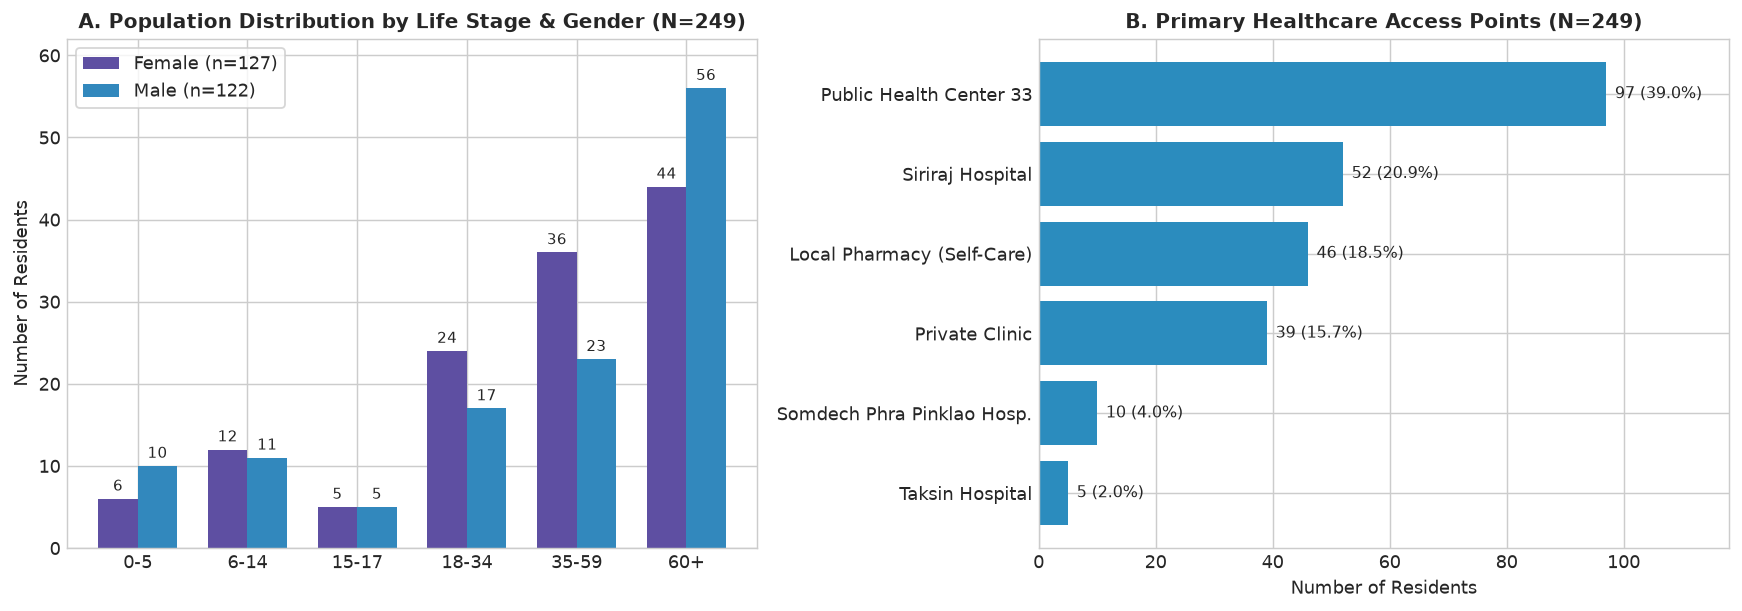

In [3]:
# Demographic summary table & visualization
demo_table = pd.DataFrame({
    'Count (n)': df_ind['Life_Stage'].value_counts().sort_index(),
    'Share (%)': (df_ind['Life_Stage'].value_counts(normalize=True).sort_index() * 100).round(2),
    'Chronic Disease (%)': df_ind.groupby('Life_Stage', observed=False)['จำแนกการเป็นโรค'].apply(lambda s: round((s == 'เป็นโรค').mean() * 100, 1)),
    'Mean Monthly Income (THB)': df_ind.groupby('Life_Stage', observed=False)['รายได้ (ต่อเดือน) -1-'].mean().round(0).astype(int)
})
display(demo_table)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Panel A: Age Structure by Gender
stages_short = ['0-5', '6-14', '15-17', '18-34', '35-59', '60+']
df_ind['Stage_Short'] = pd.cut(df_ind['อายุ'], bins=age_bins, labels=stages_short)
ct_gender = pd.crosstab(df_ind['Stage_Short'], df_ind['เพศ'])
x = np.arange(len(stages_short))
w = 0.36
b_f = axes[0].bar(x - w/2, ct_gender['หญิง'], width=w, label='Female (n=127)', color='#5e4fa2')
b_m = axes[0].bar(x + w/2, ct_gender['ชาย'], width=w, label='Male (n=122)', color='#3288bd')
axes[0].set_title('A. Population Distribution by Life Stage & Gender (N=249)', fontweight='bold', fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(stages_short)
axes[0].set_ylabel('Number of Residents')
axes[0].set_ylim(0, 62)
axes[0].legend(frameon=True)
for bars in [b_f, b_m]:
    for bar in bars:
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f"{int(bar.get_height())}", ha='center', fontsize=8.5)

# Panel B: Healthcare Facility Access
fac_map = {
    'ศูนย์บริการสาธารณสุข33': 'Public Health Center 33',
    'โรงพยาบาลศิริราช': 'Siriraj Hospital',
    'ร้านขายยา': 'Local Pharmacy (Self-Care)',
    'คลินิก': 'Private Clinic',
    'โรงพยาบาลสมเด็จพระปิ่นเกล้า': 'Somdech Phra Pinklao Hosp.',
    'โรงพยาบาลตากสิน': 'Taksin Hospital'
}
fac_counts = df_ind['การสนับสนุนจากศูนย์ฯ(การเข้าถึง) 18 ปีขึ้นไป'].map(fac_map).value_counts().sort_values()
bars_fac = axes[1].barh(fac_counts.index, fac_counts.values, color='#2b8cbe')
axes[1].set_title('B. Primary Healthcare Access Points (N=249)', fontweight='bold', fontsize=11)
axes[1].set_xlabel('Number of Residents')
axes[1].set_xlim(0, 118)
for bar in bars_fac:
    pct = bar.get_width() / len(df_ind) * 100
    axes[1].text(bar.get_width() + 1.5, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width())} ({pct:.1f}%)", va='center', fontsize=9)

plt.tight_layout()
plt.show()

---
## 3. Non-Communicable Diseases (NCDs) & Behavioral Risk Drivers

Overall, **53.82%** (134/249) of the community has at least one diagnosed chronic condition—led by **hypertension**, **diabetes**, **dyslipidemia**, **heart disease**, and **chronic kidney disease** (with 36 residents managing multi-morbid combinations).

### Key Statistical Findings (Residents Aged 15+, $n = 210$):
* **Dietary Seasoning Is the Strongest Behavioral Correlate:** **79.31%** (115/145) of residents who regularly eat strongly seasoned food (`รสจัด` — salty/sweet) have a chronic disease, compared to just **16.92%** (11/65) among those preferring mild/bland food (`รสจืด`) ($\chi^2 = 70.21, p = 5.33 	imes 10^{-17}$).
* **Habitual Sugary Beverage Consumption:** **53.41%** (133/249) drink sweetened beverages (`น้ำหวาน` — sodas, sweetened tea/coffee) regularly instead of plain water, peaking at **80.0%** in adolescents (15–17) and **74.0%** in seniors (60+).
* **High BMI, Inactivity & Substance Use:** **68.02%** (168/247 valid) are overweight or obese (`น้ำหนักเกิน` 39.3%, `อ้วนระดับ 1` 17.0%, `อ้วนระดับ 2` 11.7%). Among ages 15+ ($n=210$), only **25.71%** (54/210) meet the regular exercise threshold ($\ge 3	imes$/week, $\ge 30$ min), while **43.81%** (92/210) smoke and **40.95%** (86/210) consume alcohol.

,Hypothesis Tested,Test,Statistic,p-value,Key Comparison
0,Age 60+ vs. Chronic Disease Prevalence,Chi-Square,χ² = 111.29,5.10e-26,95.0% (60+) vs. 26.2% (<60)
1,Strong Seasoning (รสจัด) vs. Chronic Disease (...,Chi-Square,χ² = 70.21,5.33e-17,79.3% (Strong) vs. 16.9% (Mild)


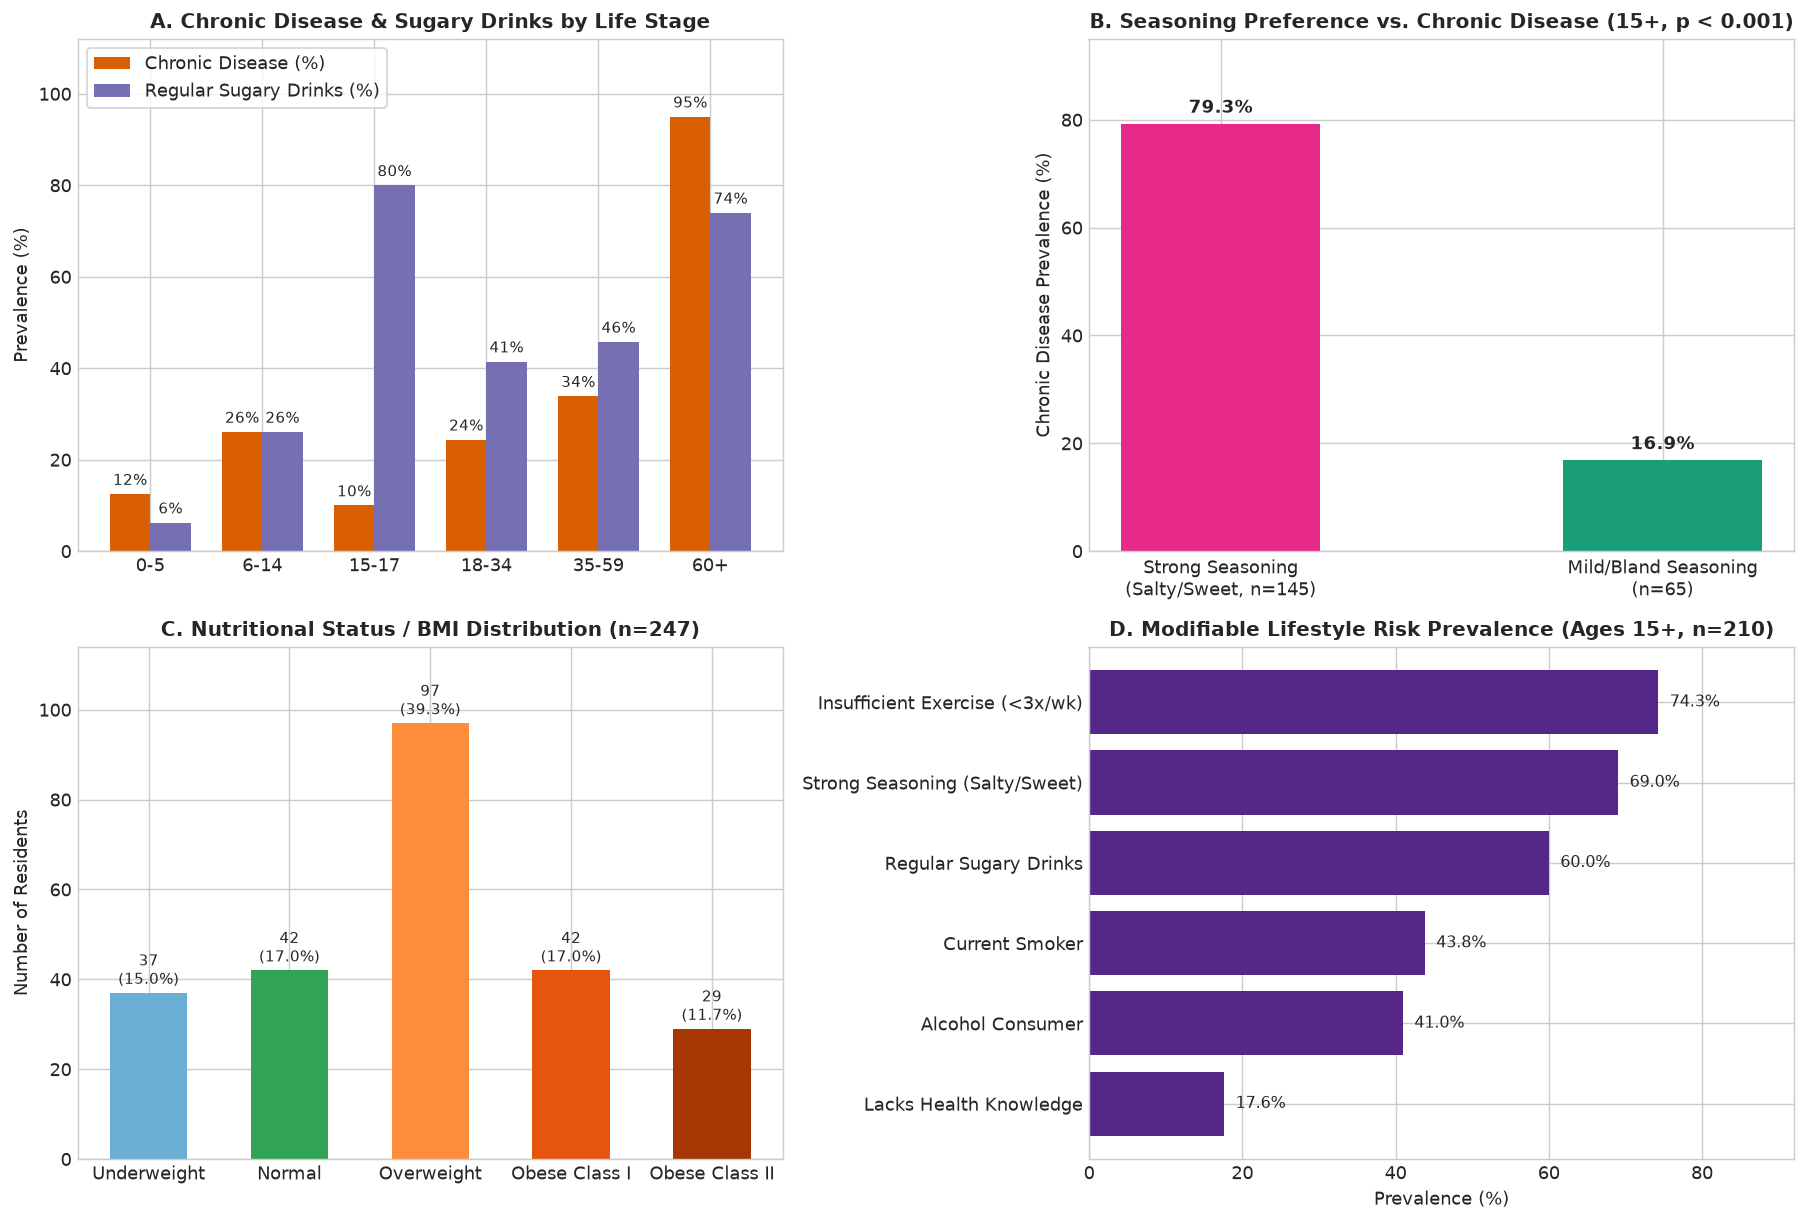

In [4]:
ind15 = df_ind[df_ind['อายุ'] >= 15].copy()

# Chi-square test: Dietary Seasoning vs Chronic Disease
ct_taste = pd.crosstab(ind15['รสชาติอาหารที่รับประทานเป็นประจำ'], ind15['จำแนกการเป็นโรค'])
chi2_taste, p_taste, _, _ = stats.chi2_contingency(ct_taste)

# Chi-square test: Age (<60 vs 60+) vs Chronic Disease
ct_age60 = pd.crosstab(df_ind['อายุ'] >= 60, df_ind['จำแนกการเป็นโรค'])
chi2_age60, p_age60, _, _ = stats.chi2_contingency(ct_age60)

stat_df = pd.DataFrame([
    {'Hypothesis Tested': 'Age 60+ vs. Chronic Disease Prevalence', 'Test': 'Chi-Square', 'Statistic': f'χ² = {chi2_age60:.2f}', 'p-value': f'{p_age60:.2e}', 'Key Comparison': '95.0% (60+) vs. 26.2% (<60)'},
    {'Hypothesis Tested': 'Strong Seasoning (รสจัด) vs. Chronic Disease (15+)', 'Test': 'Chi-Square', 'Statistic': f'χ² = {chi2_taste:.2f}', 'p-value': f'{p_taste:.2e}', 'Key Comparison': '79.3% (Strong) vs. 16.9% (Mild)'}
])
display(stat_df)

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

# 1. Chronic Disease & Sugary Drink Rate by Age
dis_rate = df_ind.groupby('Stage_Short', observed=False)['จำแนกการเป็นโรค'].apply(lambda s: (s == 'เป็นโรค').mean() * 100)
drink_rate = df_ind.groupby('Stage_Short', observed=False)['ประเภทเครื่องดื่มที่เป็นประจำ'].apply(lambda s: (s == 'น้ำหวาน').mean() * 100)
x = np.arange(len(stages_short))
w = 0.36
b1 = axes[0, 0].bar(x - w/2, dis_rate, width=w, label='Chronic Disease (%)', color='#d95f02')
b2 = axes[0, 0].bar(x + w/2, drink_rate, width=w, label='Regular Sugary Drinks (%)', color='#7570b3')
axes[0, 0].set_title('A. Chronic Disease & Sugary Drinks by Life Stage', fontweight='bold', fontsize=11)
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(stages_short)
axes[0, 0].set_ylabel('Prevalence (%)')
axes[0, 0].set_ylim(0, 112)
axes[0, 0].legend(loc='upper left', frameon=True)
for bars in [b1, b2]:
    for bar in bars:
        axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f"{bar.get_height():.0f}%", ha='center', fontsize=8.5)

# 2. Dietary Seasoning vs Chronic Disease (15+)
taste_rates = [
    (ind15[ind15['รสชาติอาหารที่รับประทานเป็นประจำ'] == 'รสจัด']['จำแนกการเป็นโรค'] == 'เป็นโรค').mean() * 100,
    (ind15[ind15['รสชาติอาหารที่รับประทานเป็นประจำ'] == 'รสจืด']['จำแนกการเป็นโรค'] == 'เป็นโรค').mean() * 100
]
b_taste = axes[0, 1].bar(['Strong Seasoning\n(Salty/Sweet, n=145)', 'Mild/Bland Seasoning\n(n=65)'],
                         taste_rates, color=['#e7298a', '#1b9e77'], width=0.45)
axes[0, 1].set_title('B. Seasoning Preference vs. Chronic Disease (15+, p < 0.001)', fontweight='bold', fontsize=11)
axes[0, 1].set_ylabel('Chronic Disease Prevalence (%)')
axes[0, 1].set_ylim(0, 95)
for bar in b_taste:
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f"{bar.get_height():.1f}%", ha='center', fontweight='bold', fontsize=10)

# 3. BMI Distribution (Valid n=247)
bmi_valid = df_ind[df_ind['BMI-4-'] != 'ไม่เกี่ยวข้อง']['BMI-4-']
bmi_order = ['ผอม', 'ปกติ', 'น้ำหนักเกิน', 'อ้วนระดับ 1', 'อ้วนระดับ 2']
bmi_labels = ['Underweight', 'Normal', 'Overweight', 'Obese Class I', 'Obese Class II']
bmi_vals = [bmi_valid.value_counts().get(k, 0) for k in bmi_order]
bmi_colors = ['#6baed6', '#31a354', '#fd8d3c', '#e6550d', '#a63603']
b_bmi = axes[1, 0].bar(bmi_labels, bmi_vals, color=bmi_colors, width=0.55)
axes[1, 0].set_title('C. Nutritional Status / BMI Distribution (n=247)', fontweight='bold', fontsize=11)
axes[1, 0].set_ylabel('Number of Residents')
axes[1, 0].set_ylim(0, 114)
for bar in b_bmi:
    pct = bar.get_height() / len(bmi_valid) * 100
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f"{int(bar.get_height())}\n({pct:.1f}%)", ha='center', fontsize=8.5)

# 4. Modifiable Behavioral Risks in Ages 15+ (n=210)
risk_15 = {
    'Insufficient Exercise (<3x/wk)': (~ind15['ความสม่ำเสมอในการออกกำลังกาย'].str.startswith('≥3', na=False)).mean() * 100,
    'Strong Seasoning (Salty/Sweet)': (ind15['รสชาติอาหารที่รับประทานเป็นประจำ'] == 'รสจัด').mean() * 100,
    'Regular Sugary Drinks': (ind15['ประเภทเครื่องดื่มที่เป็นประจำ'] == 'น้ำหวาน').mean() * 100,
    'Current Smoker': (ind15['พฤติกรรมสูบบุหรี่ 15 ปีขึ้นไป'] == 'สูบบุหรี่').mean() * 100,
    'Alcohol Consumer': (ind15['พฤติกรรมการดื่มแอลกอฮอล์ 15 ปีขึ้นไป'] == 'ดื่ม').mean() * 100,
    'Lacks Health Knowledge': (ind15['มีความรู้เกี่ยวกับการดูแลสุขภาพ 15 ปีขึ้นไป'] == 'ไม่มี').mean() * 100
}
s_r15 = pd.Series(risk_15).sort_values()
b_r15 = axes[1, 1].barh(s_r15.index, s_r15.values, color='#542788')
axes[1, 1].set_title('D. Modifiable Lifestyle Risk Prevalence (Ages 15+, n=210)', fontweight='bold', fontsize=11)
axes[1, 1].set_xlabel('Prevalence (%)')
axes[1, 1].set_xlim(0, 92)
for bar in b_r15:
    axes[1, 1].text(bar.get_width() + 1.5, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.1f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()

---
## 4. Geriatric Vulnerability, Fall Risk & Caregiver Deficit (60+, $n = 100$)

The 100 older adults represent the community's highest-acuity cohort, exhibiting overlapping musculoskeletal, neurological, and cardiovascular vulnerabilities:
* **Mobility & Fall Risk:** **59.0%** have knee osteoarthritis, **39.0%** have impaired balance, and **28.0%** experienced $\ge 2$ falls in the past 6 months. The **Thai FRAT** fall-risk screening tool strongly discriminates fallers (mean = **7.04**, $	ext{SD} = 1.95$) from non-fallers (mean = **1.27**, $	ext{SD} = 1.83$; Mann-Whitney $p < 0.001$).
* **Cognitive & Sensory Decline:** **22.0%** screen positive for suspected dementia, **23.0%** have hearing impairment, **22.0%** have vision impairment, and **21.0%** report urinary incontinence.
* **The Caregiver Gap:** While all **13** physically dependent seniors (`ADL <= 11`) have a caregiver (7 hired, 6 family), **50.0% (11/22)** of seniors with suspected dementia and **64.3% (18/28)** of recurrent fallers have **no caregiver (`ไม่มี`)**—creating acute risk for unattended home injuries and medication errors.

Thai FRAT Faller Validation: Fallers Mean = 7.04 (SD=1.95) vs. Non-Fallers Mean = 1.27 (SD=1.83), Mann-Whitney p = 3.09e-19


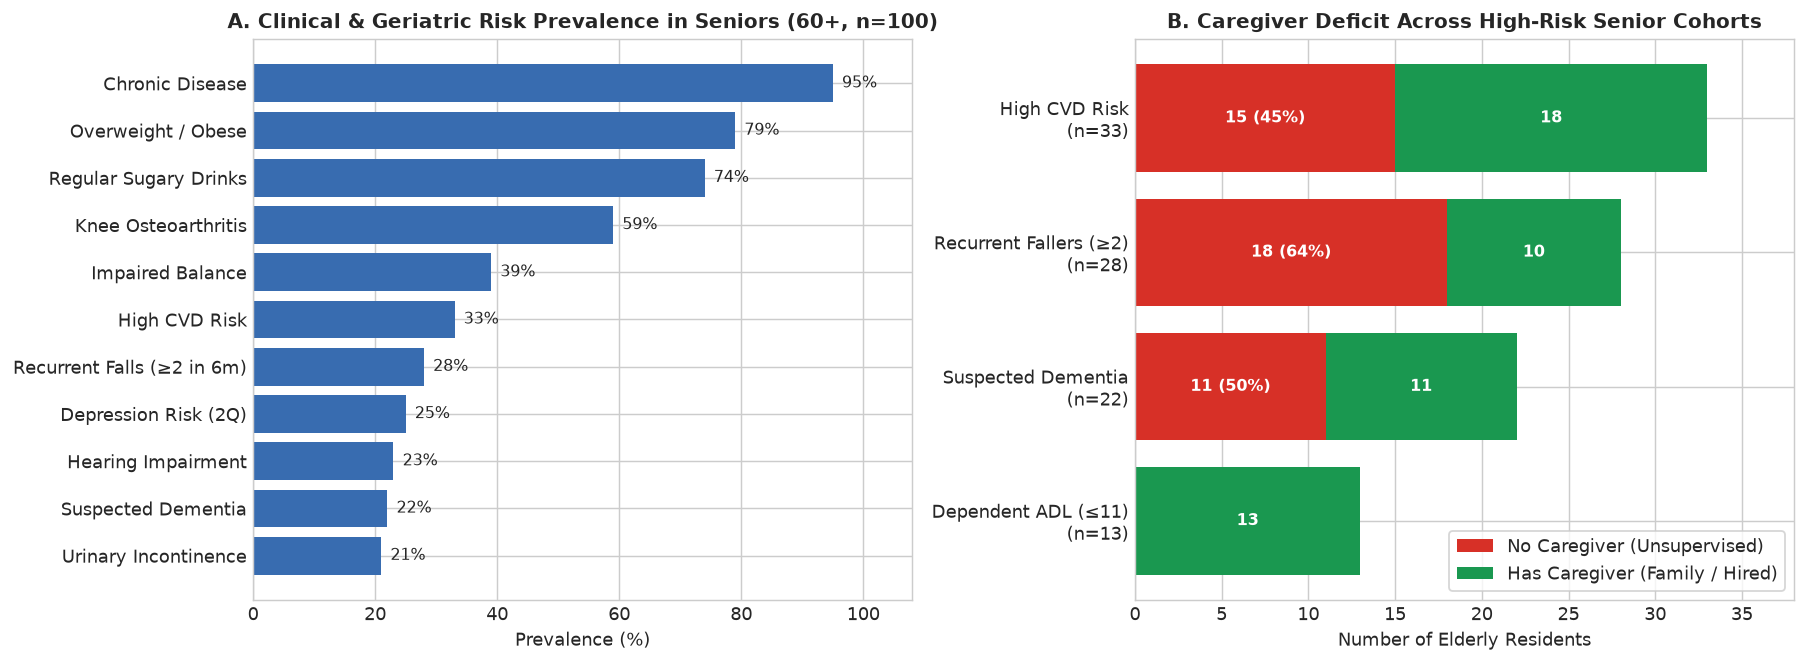

In [5]:
eld = df_ind[df_ind['อายุ'] >= 60].copy()

# Mann-Whitney U test for Thai FRAT scores between fallers and non-fallers
fallers_frat = df_ind[df_ind['เคยหกล้ม 2 ครั้งขึ้นไป ใน 6 เดือนที่ผ่านมา'] == 'เคย']['คะแนน Thai FRAT']
nonfallers_frat = df_ind[df_ind['เคยหกล้ม 2 ครั้งขึ้นไป ใน 6 เดือนที่ผ่านมา'] == 'ไม่เคย']['คะแนน Thai FRAT']
u_stat, p_frat = stats.mannwhitneyu(fallers_frat, nonfallers_frat)
print(f"Thai FRAT Faller Validation: Fallers Mean = {fallers_frat.mean():.2f} (SD={fallers_frat.std():.2f}) vs. Non-Fallers Mean = {nonfallers_frat.mean():.2f} (SD={nonfallers_frat.std():.2f}), Mann-Whitney p = {p_frat:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Panel A: Geriatric Risk Prevalence
eld_risks = {
    'Chronic Disease': (eld['จำแนกการเป็นโรค'] == 'เป็นโรค').mean() * 100,
    'Overweight / Obese': eld['BMI-4-'].isin(['น้ำหนักเกิน', 'อ้วนระดับ 1', 'อ้วนระดับ 2']).mean() * 100,
    'Regular Sugary Drinks': (eld['ประเภทเครื่องดื่มที่เป็นประจำ'] == 'น้ำหวาน').mean() * 100,
    'Knee Osteoarthritis': (eld['ปัญหาข้อเข่าเสื่อม 35 ปีขึ้นไป-2-'] == 'เข่าเสื่อม').mean() * 100,
    'Impaired Balance': (eld['การทรงตัว'] == 'บกพร่อง').mean() * 100,
    'High CVD Risk': (eld['Thai CVD Risk Score -4-'] == 'สูง').mean() * 100,
    'Recurrent Falls (≥2 in 6m)': (eld['เคยหกล้ม 2 ครั้งขึ้นไป ใน 6 เดือนที่ผ่านมา'] == 'เคย').mean() * 100,
    'Depression Risk (2Q)': (eld['แบบประเมิน 2Q 15 ปีขึ้นไป'] == 'เสี่ยง').mean() * 100,
    'Hearing Impairment': (eld['ปัญหาการได้ยิน-2-'] == 'ผิดปกติ').mean() * 100,
    'Suspected Dementia': (eld['ปัญหาสมรรถภาพสมอง 60 ปีขึ้นไป-2-'] == 'สงสัยสมองเสื่อม').mean() * 100,
    'Urinary Incontinence': (eld['ปัญหาการกลั้นปัสสาวะ-2-'] == 'มี').mean() * 100,
}
s_eld = pd.Series(eld_risks).sort_values()
b_eld = axes[0].barh(s_eld.index, s_eld.values, color='#386cb0')
axes[0].set_title('A. Clinical & Geriatric Risk Prevalence in Seniors (60+, n=100)', fontweight='bold', fontsize=11)
axes[0].set_xlabel('Prevalence (%)')
axes[0].set_xlim(0, 108)
for bar in b_eld:
    axes[0].text(bar.get_width() + 1.5, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.0f}%", va='center', fontsize=8.8)

# Panel B: Caregiver Coverage Gap in High-Risk Seniors
cohorts = {
    'Dependent ADL (≤11)\n(n=13)': eld[eld['ADL_num'] <= 11],
    'Suspected Dementia\n(n=22)': eld[eld['ปัญหาสมรรถภาพสมอง 60 ปีขึ้นไป-2-'] == 'สงสัยสมองเสื่อม'],
    'Recurrent Fallers (≥2)\n(n=28)': eld[eld['เคยหกล้ม 2 ครั้งขึ้นไป ใน 6 เดือนที่ผ่านมา'] == 'เคย'],
    'High CVD Risk\n(n=33)': eld[eld['Thai CVD Risk Score -4-'] == 'สูง']
}
no_cg = [ (sub['ผู้ดูแล-4-'] == 'ไม่มี').sum() for sub in cohorts.values() ]
has_cg = [ (sub['ผู้ดูแล-4-'] != 'ไม่มี').sum() for sub in cohorts.values() ]
y_pos = np.arange(len(cohorts))

axes[1].barh(y_pos, no_cg, color='#d73027', label='No Caregiver (Unsupervised)')
axes[1].barh(y_pos, has_cg, left=no_cg, color='#1a9850', label='Has Caregiver (Family / Hired)')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(list(cohorts.keys()))
axes[1].set_xlabel('Number of Elderly Residents')
axes[1].set_title('B. Caregiver Deficit Across High-Risk Senior Cohorts', fontweight='bold', fontsize=11)
axes[1].set_xlim(0, 38)
axes[1].legend(loc='lower right', frameon=True)
for i, (n0, n1) in enumerate(zip(no_cg, has_cg)):
    tot = n0 + n1
    if n0 > 0:
        axes[1].text(n0 / 2, i, f"{n0} ({n0/tot*100:.0f}%)", ha='center', va='center', color='white', fontweight='bold', fontsize=9)
    if n1 > 0:
        axes[1].text(n0 + n1 / 2, i, f"{n1}", ha='center', va='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

---
## 5. Mental Health, Sleep Disruption & Pediatric Screening

* **Pervasive Insomnia:** **65.86%** (164/249) of residents report sleep difficulties (`เป็นบางวัน` 33.73%, `เป็นประจำ` 32.13%), spanning both working-age adults and seniors.
* **Depression & Stress Screening (Ages 15+):** **19.14%** (40/209) screen positive on the **2Q depression screen** (`เสี่ยง`), and **15.24%** (32/210) experience high or severe stress on **ST-5** (`มาก` 30, `มากที่สุด` 2).
* **Children & Youth (0–18):** **53.85%** (28/52) of screened children and adolescents have untreated **dental caries (`มีฟันผุ`)**. Among early childhood (0–5, $n=17$), **3 children** show below-standard physical growth, **3** show fine-motor delay, and **3** show language/communication delay.

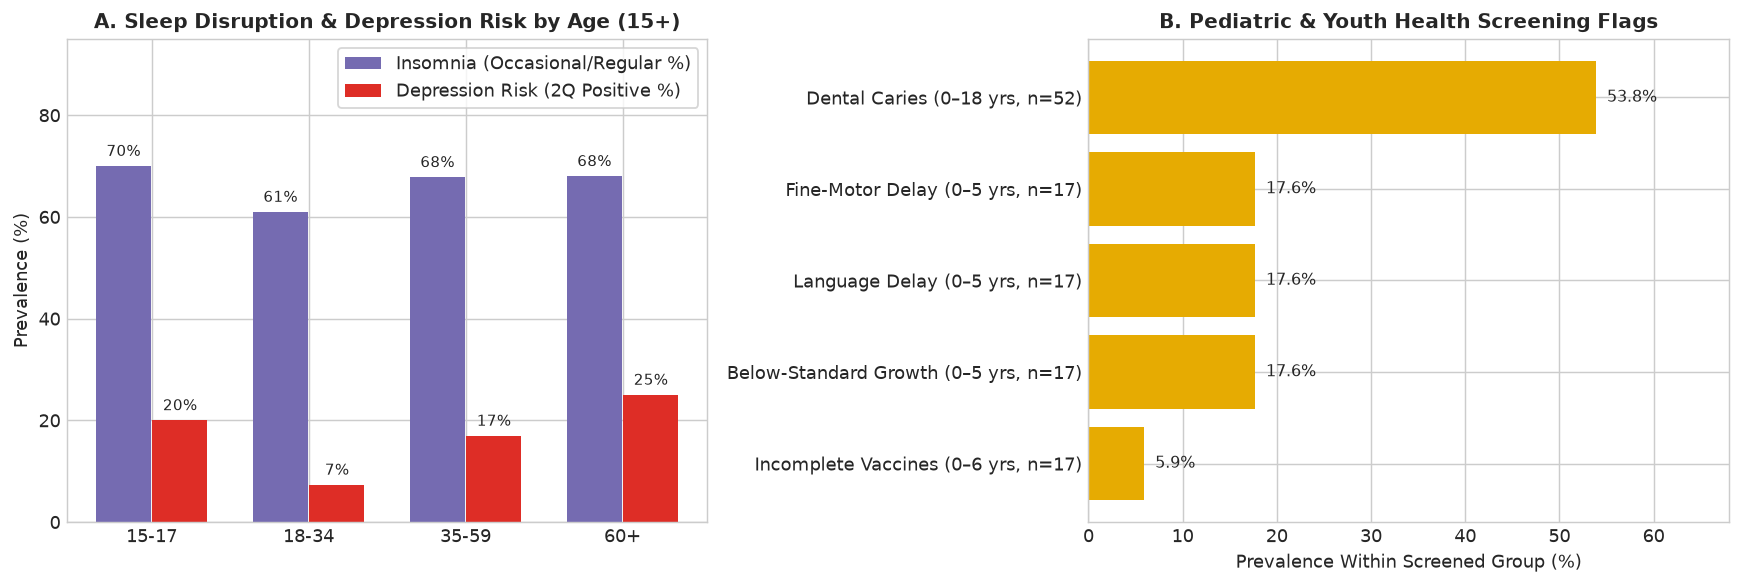

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

# Panel A: Insomnia & Depression Risk by Adult Life Stage
adult_stages = ['15-17', '18-34', '35-59', '60+']
df_adult = df_ind[df_ind['Stage_Short'].isin(adult_stages)]
insomnia_any = df_adult.groupby('Stage_Short', observed=True)['ปัญหาการนอนไม่หลับ-2-'].apply(lambda s: (s != 'ไม่มี').mean() * 100)
dep_2q = df_adult.groupby('Stage_Short', observed=True)['แบบประเมิน 2Q 15 ปีขึ้นไป'].apply(lambda s: (s == 'เสี่ยง').mean() * 100)

xa = np.arange(len(adult_stages))
b_ins = axes[0].bar(xa - 0.18, insomnia_any, width=0.35, label='Insomnia (Occasional/Regular %)', color='#756bb1')
b_dep = axes[0].bar(xa + 0.18, dep_2q, width=0.35, label='Depression Risk (2Q Positive %)', color='#de2d26')
axes[0].set_title('A. Sleep Disruption & Depression Risk by Age (15+)', fontweight='bold', fontsize=11)
axes[0].set_xticks(xa)
axes[0].set_xticklabels(adult_stages)
axes[0].set_ylabel('Prevalence (%)')
axes[0].set_ylim(0, 95)
axes[0].legend(frameon=True)
for bars in [b_ins, b_dep]:
    for bar in bars:
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f"{bar.get_height():.0f}%", ha='center', fontsize=8.5)

# Panel B: Pediatric & Youth Screening Findings
ped_items = {
    'Dental Caries (0–18 yrs, n=52)': 28 / 52 * 100,
    'Below-Standard Growth (0–5 yrs, n=17)': 3 / 17 * 100,
    'Fine-Motor Delay (0–5 yrs, n=17)': 3 / 17 * 100,
    'Language Delay (0–5 yrs, n=17)': 3 / 17 * 100,
    'Incomplete Vaccines (0–6 yrs, n=17)': 1 / 17 * 100
}
s_ped = pd.Series(ped_items).sort_values()
b_ped = axes[1].barh(s_ped.index, s_ped.values, color='#e6ab02')
axes[1].set_title('B. Pediatric & Youth Health Screening Flags', fontweight='bold', fontsize=11)
axes[1].set_xlabel('Prevalence Within Screened Group (%)')
axes[1].set_xlim(0, 68)
for bar in b_ped:
    axes[1].text(bar.get_width() + 1.2, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.1f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()

---
## 6. Household Socioeconomics, Family Dynamics & Sanitation ($N = 66$)

Analyzing the 66 household records uncovers a powerful structural link between **household poverty**, **intra-family conflict**, **unhealthy cooking practices**, and **environmental sanitation deficits**:

1. **Income Gradient of Family Conflict ($p < 0.001$):** Over half of surveyed households (**53.03%**, 35/66) report strained family relationships—including **33.33%** (22/66) frequent arguments (`ทะเลาะกันบ่อย`) and **12.12%** (8/66) domestic violence (`มีการใช้ความรุนแรง`). Harmonious households (`สัมพันธภาพดี`) earn a mean of **17,129 THB/month**, nearly **3x higher** than households with frequent arguments (**6,095 THB**) or domestic violence (**6,250 THB**, where 100% earn $\le 8,200$ THB/month; Kruskal-Wallis $H = 41.74, p = 1.89 	imes 10^{-8}$).
2. **Income Shapes Cooking Methods:** Households using healthier boiled preparation (`ต้ม`, $n=12$) earn a mean of **25,167 THB/month** (min 18,000 THB), whereas households relying on frying (`ทอด`, $n=33$) earn **5,985 THB/month** (max 9,200 THB).
3. **Waste Sorting, Vector Inaction & Low Social Capital:** **72.73%** (48/66) either do not sort waste (**56.06%**) or sort incorrectly (**16.67%**), contributing to **39.39%** (26/66) experiencing odor nuisance. Among the **32 households** reporting disease vectors (mosquitoes, flies, cockroaches, rats), **78.13%** (25/32) take **no elimination action**. At the community level, **100%** (199/199) of adult respondents report community non-cooperation (`ไม่ให้ความร่วมมือ`) and **54.27%** report community conflict.

,Households,Mean_Income_THB,Median_Income_THB,Max_Income_THB,Share (%)
สัมพันธภาพครอบครัว,,,,,
สัมพันธภาพดี,31,17129.0,14500.0,40000.0,46.97
ต่างคนต่างอยู่,3,10267.0,12500.0,13500.0,4.55
ทะเลาะกันบ้าง,2,9950.0,9950.0,14500.0,3.03
มีการใช้ความรุนแรง,8,6250.0,7000.0,8200.0,12.12
ทะเลาะกันบ่อย,22,6095.0,5900.0,15000.0,33.33


Kruskal-Wallis Test (Income vs. Family Relationship): H = 41.74, p = 1.89e-08


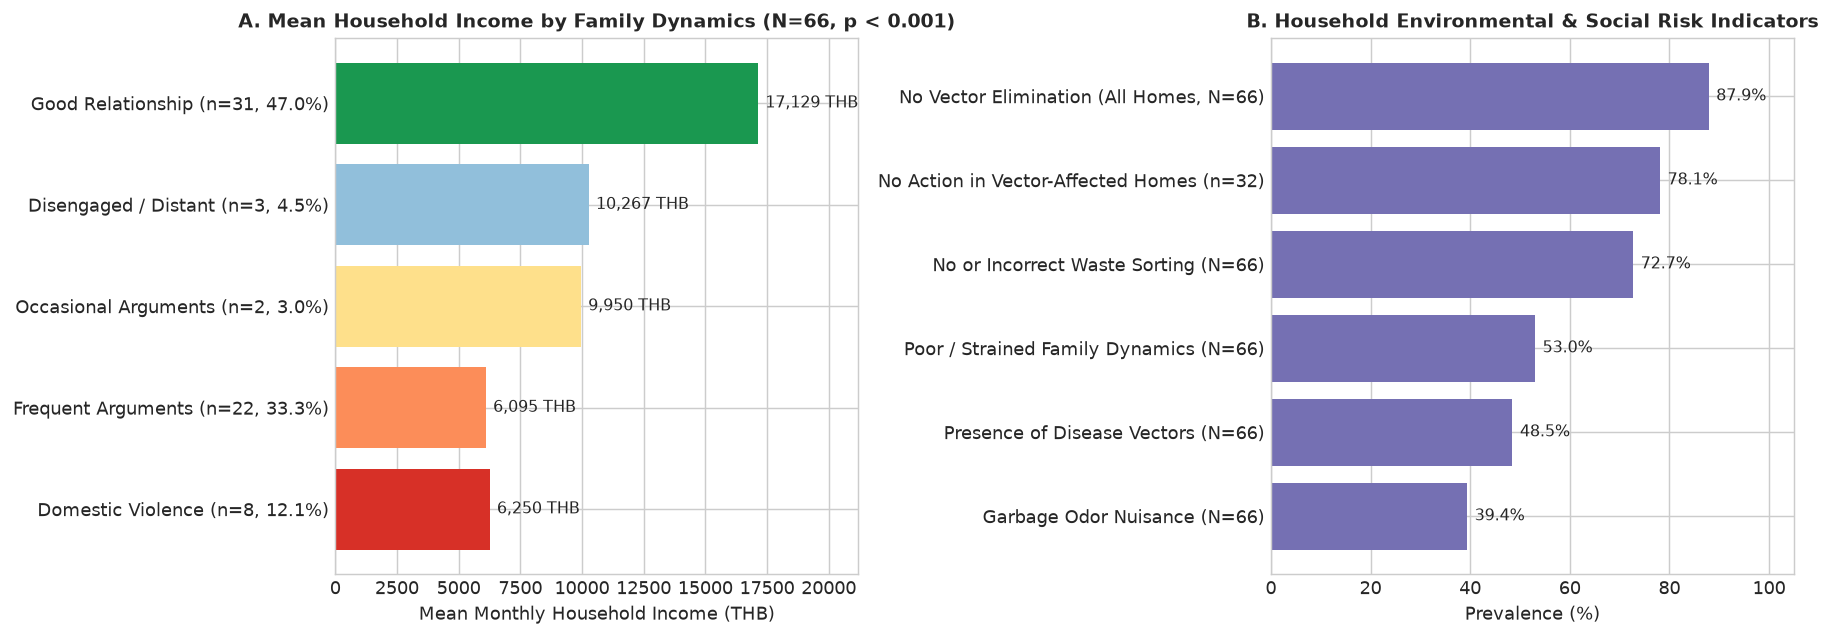

In [7]:
# Kruskal-Wallis test: Household Income across Family Relationship categories
rel_groups = [g['รายได้ (ต่อเดือน)'].values for _, g in df_hh.groupby('สัมพันธภาพครอบครัว')]
kw_h, kw_p = stats.kruskal(*rel_groups)

hh_rel_summary = df_hh.groupby('สัมพันธภาพครอบครัว')['รายได้ (ต่อเดือน)'].agg(
    Households='count',
    Mean_Income_THB=lambda s: round(s.mean(), 0),
    Median_Income_THB=lambda s: round(s.median(), 0),
    Max_Income_THB='max'
).sort_values('Mean_Income_THB', ascending=False)
hh_rel_summary['Share (%)'] = (hh_rel_summary['Households'] / len(df_hh) * 100).round(2)
display(hh_rel_summary)
print(f"Kruskal-Wallis Test (Income vs. Family Relationship): H = {kw_h:.2f}, p = {kw_p:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))

# Panel A: Household Income by Family Dynamics
rel_labels = {
    'มีการใช้ความรุนแรง': 'Domestic Violence (n=8, 12.1%)',
    'ทะเลาะกันบ่อย': 'Frequent Arguments (n=22, 33.3%)',
    'ทะเลาะกันบ้าง': 'Occasional Arguments (n=2, 3.0%)',
    'ต่างคนต่างอยู่': 'Disengaged / Distant (n=3, 4.5%)',
    'สัมพันธภาพดี': 'Good Relationship (n=31, 47.0%)'
}
order_rel = ['มีการใช้ความรุนแรง', 'ทะเลาะกันบ่อย', 'ทะเลาะกันบ้าง', 'ต่างคนต่างอยู่', 'สัมพันธภาพดี']
means_rel = [df_hh[df_hh['สัมพันธภาพครอบครัว'] == k]['รายได้ (ต่อเดือน)'].mean() for k in order_rel]
colors_rel = ['#d73027', '#fc8d59', '#fee08b', '#91bfdb', '#1a9850']

b_rel = axes[0].barh([rel_labels[k] for k in order_rel], means_rel, color=colors_rel)
axes[0].set_title('A. Mean Household Income by Family Dynamics (N=66, p < 0.001)', fontweight='bold', fontsize=10.5)
axes[0].set_xlabel('Mean Monthly Household Income (THB)')
axes[0].set_xlim(0, 21200)
for bar in b_rel:
    axes[0].text(bar.get_width() + 300, bar.get_y() + bar.get_height()/2, f"{bar.get_width():,.0f} THB", va='center', fontsize=9)

# Panel B: Household Environmental & Sanitation Deficits
san_metrics = {
    'No Vector Elimination (All Homes, N=66)': (df_hh['การกำจัดสัตว์พาหะ'] == 'ไม่กำจัด').mean() * 100,
    'No Action in Vector-Affected Homes (n=32)': (df_hh[df_hh['สัตว์ที่เป็นพาหะนำโรค'] == 'มี']['การกำจัดสัตว์พาหะ'] == 'ไม่กำจัด').mean() * 100,
    'No or Incorrect Waste Sorting (N=66)': (df_hh['ความถูกต้องในการแยกประเภทขยะ'] != 'แยกขยะถูก').mean() * 100,
    'Poor / Strained Family Dynamics (N=66)': (df_hh['สัมพันธภาพครอบครัว'] != 'สัมพันธภาพดี').mean() * 100,
    'Presence of Disease Vectors (N=66)': (df_hh['สัตว์ที่เป็นพาหะนำโรค'] == 'มี').mean() * 100,
    'Garbage Odor Nuisance (N=66)': (df_hh['ปัญหากลิ่นขยะะรบกวน'] == 'มี').mean() * 100
}
s_san = pd.Series(san_metrics).sort_values()
b_san = axes[1].barh(s_san.index, s_san.values, color='#7570b3')
axes[1].set_title('B. Household Environmental & Social Risk Indicators', fontweight='bold', fontsize=10.5)
axes[1].set_xlabel('Prevalence (%)')
axes[1].set_xlim(0, 105)
for bar in b_san:
    axes[1].text(bar.get_width() + 1.5, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.1f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()

---
## 7. Priority Case Identification & 5-Pillar Action Plan

To make this analysis immediately operational for community health nurses, village health volunteers (`อสม.`), and Public Health Center 33, the code below extracts the exact **Priority Action Cohorts** from the dataset and pairs them with a 5-pillar intervention matrix.

In [8]:
# Extract operational target cohorts for immediate outreach
unsupervised_dementia = eld[(eld['ปัญหาสมรรถภาพสมอง 60 ปีขึ้นไป-2-'] == 'สงสัยสมองเสื่อม') & (eld['ผู้ดูแล-4-'] == 'ไม่มี')]['ลำดับ'].tolist()
unsupervised_fallers = eld[(eld['เคยหกล้ม 2 ครั้งขึ้นไป ใน 6 เดือนที่ผ่านมา'] == 'เคย') & (eld['ผู้ดูแล-4-'] == 'ไม่มี')]['ลำดับ'].tolist()
depression_risk_ids = ind15[ind15['แบบประเมิน 2Q 15 ปีขึ้นไป'] == 'เสี่ยง']['ลำดับ'].tolist()
dv_households = df_hh[df_hh['สัมพันธภาพครอบครัว'] == 'มีการใช้ความรุนแรง']['ลำดับครัวเรือน'].tolist()
untreated_vector_hh = df_hh[(df_hh['สัตว์ที่เป็นพาหะนำโรค'] == 'มี') & (df_hh['การกำจัดสัตว์พาหะ'] == 'ไม่กำจัด')]['ลำดับครัวเรือน'].tolist()

priority_registry = pd.DataFrame([
    {
        'Priority Tier': 'Tier 1: Urgent Clinical',
        'Target Cohort': 'Elderly (60+) with Suspected Dementia & No Caregiver',
        'Count': len(unsupervised_dementia),
        'Record IDs (ลำดับ / ครัวเรือน)': ', '.join(map(str, unsupervised_dementia))
    },
    {
        'Priority Tier': 'Tier 1: Urgent Clinical',
        'Target Cohort': 'Elderly (60+) Recurrent Fallers (≥2) & No Caregiver',
        'Count': len(unsupervised_fallers),
        'Record IDs (ลำดับ / ครัวเรือน)': ', '.join(map(str, unsupervised_fallers))
    },
    {
        'Priority Tier': 'Tier 1: Urgent Social Safety',
        'Target Cohort': 'Households Reporting Domestic Violence (All ≤8,200 THB/mo)',
        'Count': len(dv_households),
        'Record IDs (ลำดับ / ครัวเรือน)': ', '.join(map(str, dv_households))
    },
    {
        'Priority Tier': 'Tier 2: Mental Health',
        'Target Cohort': 'Residents (15+) Screening Positive on 2Q Depression Screen',
        'Count': len(depression_risk_ids),
        'Record IDs (ลำดับ / ครัวเรือน)': f"{len(depression_risk_ids)} individuals (e.g., IDs {', '.join(map(str, depression_risk_ids[:8]))}...)"
    },
    {
        'Priority Tier': 'Tier 2: Environmental',
        'Target Cohort': 'Vector-Affected Households Taking Zero Elimination Action',
        'Count': len(untreated_vector_hh),
        'Record IDs (ลำดับ / ครัวเรือน)': ', '.join(map(str, untreated_vector_hh))
    }
])
display(priority_registry)

,Priority Tier,Target Cohort,Count,Record IDs (ลำดับ / ครัวเรือน)
0,Tier 1: Urgent Clinical,Elderly (60+) with Suspected Dementia & No Car...,11,"1, 20, 35, 51, 12, 108, 247, 27, 90, 248, 24"
1,Tier 1: Urgent Clinical,Elderly (60+) Recurrent Fallers (≥2) & No Care...,18,"60, 151, 246, 247, 28, 244, 27, 90, 116, 148, ..."
2,Tier 1: Urgent Social Safety,Households Reporting Domestic Violence (All ≤8...,8,"1, 8, 13, 19, 25, 26, 27, 28"
3,Tier 2: Mental Health,Residents (15+) Screening Positive on 2Q Depre...,40,"40 individuals (e.g., IDs 48, 130, 168, 83, 98..."
4,Tier 2: Environmental,Vector-Affected Households Taking Zero Elimina...,25,"1, 2, 3, 5, 11, 12, 13, 24, 25, 26, 27, 28, 32..."


### 5-Pillar Community Health Action Plan

| Pillar | Target Group | Baseline Metric | Actionable Intervention | Lead Partners |
| :--- | :--- | :--- | :--- | :--- |
| **1. Geriatric Fall & Dementia Care** | 100 Elderly (esp. **11** dementia & **18** fallers without caregivers) | **28%** recurrent falls; **64.3%** fallers unsupervised | Enroll unsupervised high-FRAT ($\ge 4$) and dementia seniors into Long-Term Care (LTC) home visits; install grab bars/non-slip mats; run knee-strengthening & balance clinics for the **59** knee OA cases. | Public Health Center 33, Village Health Volunteers (`อสม.`), District Social Welfare |
| **2. Low-Sodium, Zero-Sugar Nutrition** | Residents 15+ (**145** strong-flavor eaters; **133** sugary drink users) | **79.3%** NCD rate in `รสจัด` eaters vs. **16.9%** in `รสจืด` | Replace daily `น้ำหวาน` (74% of seniors, 80% of teens) with infused/plain water; run budget-friendly low-oil/boiled cooking workshops tailored for low-income households (`<9,200` THB) reliant on fried food. | Public Health Center 33 Nutritionists, Siriraj Community Outreach |
| **3. Mental Health & Family Safety** | **40** `2Q` positive; **164** insomnia; **8** domestic violence & **22** high-conflict homes | **19.1%** depression risk; **12.1%** domestic violence | Conduct `9Q` clinical follow-ups and community sleep-hygiene sessions; establish confidential social-work & micro-financial support referrals for the **8** low-income domestic violence households. | Public Health Center 33 Mental Health Clinic, MSDHS (`พม.`) |
| **4. Vector Control & Waste Sorting** | **25** untreated vector homes; **48** non/improper waste-sorting homes | **78.1%** vector inaction; **72.7%** improper waste sorting | Conduct door-to-door larvicidal sand (`ทรายอะเบท`) distribution and stagnant-water clearance in the **25** active vector households; install color-coded 3-bin community waste stations to cut the **39.4%** odor rate. | District Environment & Sanitation Office, Community Committee |
| **5. Pediatric Dental & Early Growth** | **52** youth (0–18); **17** early childhood (0–5) | **53.8%** dental caries; **3** growth/motor/language flags | Deliver school/community fluoride varnish & mobile dental screening for the **28** children with caries; refer the **3** early-childhood developmental flags to child development clinics. | Public Health Center 33 Dental & Well-Child Clinic |